# nb03 · L2 静态平衡性质

**目的**（`validation_methods_L0-L5.md` L2）：检查基态、相对能量和 PES 曲率。

第一阶段落地四件事：

1. cubic GST225 与 hexagonal GST225 的结构弛豫；
2. 两相的相对能量和排序；
3. 两相各自的 **fixed-volume ionic-relaxed** EOS；
4. 报告平衡体积和体模量。

DFT 侧全部来自 phase-1 已完成任务，属于 **B 级证据**（同项目协议的静态 DFT）：

| 用途 | 任务 | 状态 |
|---|---|---|
| 六角相几何 | `L1_mp1224375_relax` / `_static` | 已完成 |
| 六角相 EOS | `H2_hex_v092 … v108`（7 点） | 已完成 |
| 立方相几何 | `H1_cubic_s01…s05_relax` / `_static` | 已完成 |
| 立方相 EOS | `H2_cub01_v* … H2_cub05_v*`（5 个空位排布 × 7 点 = 35 点） | 已完成 |

> **明确排除**：`GST225_ref` 里 306 原子的 11 点体积扫描是 `NSW = 0` 的不松弛扫描。
> 框架规定它不能作为正式 EOS，`load_dft_eos` 因此在代码里直接拒绝读入 `NSW <= 0` 的任务，
> 而不是靠注释提醒。
> **2026-09-07 更新**：立方相 DFT EOS 已全部算完。五条曲线是同一个 194 原子胞的
> **五种空位排布**，不是同一件事测五次，所以它们的散布是构型性的、**不能当 `sigma_ref`**。
> 框架改为逐 seed 配对（MLIP 也在五种排布上各扫一遍），
> `L2.eos.cubic.V0_error` 报 5 个成对误差的均值，`uncertainty` 报它们的跨排布标准差。


In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, paths, protocols
from mlipeval.l2_static import EOSCurve, birch_murnaghan, fit_eos, load_dft_eos
from mlipeval.plotting import use_style

use_style()
pd.set_option("display.width", 210)
pd.set_option("display.max_colwidth", 70)

results = json.loads((paths.RESULTS / "L2_mace_mpa0.json").read_text())
by_id = {r["metric_id"]: r for r in results["results"]}
print("L2 结果条目:", len(by_id))
print("DFT 协议    :", results["context"]["dft_protocol"])
print("弛豫收敛判据:", results["context"]["fmax_eV_per_A"], "eV/A")
print("EOS 缩放点  :", results["context"]["eos_scales"])

L2 结果条目: 45
DFT 协议    : gst225_pbe_canonical_v1
弛豫收敛判据: 0.01 eV/A
EOS 缩放点  : [0.92, 0.95, 0.98, 1.0, 1.02, 1.05, 1.08]


## 1. DFT 参考任务盘点

先确认哪些 phase-1 任务是真的跑完了。判据是 VASP 写出了最终 timing 区块——
注意这个区块后面还跟着很长的 profiling dump，所以尾窗口必须开得够大
（8 kB 不够，`outcar_is_complete` 用 512 kB）。

In [2]:
rows = []
for prefix in ("L1_mp", "L2_", "H1_cubic", "H2_hex", "H2_cub", "H4_mq", "H0_"):
    done = datasets.completed_tasks(prefix)
    rows.append({"任务前缀": prefix, "已完成": len(done),
                 "示例": ", ".join(d.name for d in done[:3]) + (" …" if len(done) > 3 else "")})
display(pd.DataFrame(rows))

print("\nBLOCKED 的语义有两种记法，只认一种会丢数据：")
print("  旧执行器：上游就位后保留 BLOCKED，旁边放 BLOCKED.resolved.<jobid>；")
print("  20260831_execution_v1：改为写 MATERIALIZED_FROM（记录上游任务与变换）。")
print("只看 BLOCKED.resolved.* 会把 H2_cub01_v092 / H2_cub05_v105 / L2_sb_static")
print("这三个已完成的任务误判为未就绪。datasets.is_blocked() 两种证据都认。")

print("\n任务输出也不一定在任务目录里：新执行器把每次运行放在 runs/run_<id>/,")
print("再用 RESULT_RUN 符号链接发布通过步数校验的那一次；读取一律走 io_vasp.task_output_dir()。")


,任务前缀,已完成,示例
0,L1_mp,6,"L1_mp1224375_relax, L1_mp1224375_static, L1_mp1224407_relax …"
1,L2_,5,"L2_ge_relax, L2_ge_static, L2_sb_relax …"
2,H1_cubic,10,"H1_cubic_s01_relax, H1_cubic_s01_static, H1_cubic_s02_relax …"
3,H2_hex,7,"H2_hex_v092, H2_hex_v095, H2_hex_v098 …"
4,H2_cub,19,"H2_cub01_v095, H2_cub01_v098, H2_cub01_v100 …"
5,H4_mq,0,
6,H0_,3,"H0_preflight_01_nvt3000, H0_preflight_02_nvt1200, H0_preflight_03_..."



BLOCKED 的语义有两种记法，只认一种会丢数据：
  旧执行器：上游就位后保留 BLOCKED，旁边放 BLOCKED.resolved.<jobid>；
  20260831_execution_v1：改为写 MATERIALIZED_FROM（记录上游任务与变换）。
只看 BLOCKED.resolved.* 会把 H2_cub01_v092 / H2_cub05_v105 / L2_sb_static
这三个已完成的任务误判为未就绪。datasets.is_blocked() 两种证据都认。

任务输出也不一定在任务目录里：新执行器把每次运行放在 runs/run_<id>/,
再用 RESULT_RUN 符号链接发布通过步数校验的那一次；读取一律走 io_vasp.task_output_dir()。


## 2. 六角相与立方相的结构弛豫

MLIP 侧用 `FrechetCellFilter` + FIRE 做变胞弛豫（`FrechetCellFilter` 在大应变下的胞梯度是正确的）。
DFT 侧读 `CONTCAR`/`OUTCAR` 的终态。两侧比较的是每原子体积、胞长与相对能量。

In [3]:
hex_dft = datasets.dft_relaxed("L1_mp1224375_relax")
hex_dft_static = datasets.dft_relaxed("L1_mp1224375_static")
cubic_dft = datasets.dft_relaxed("H1_cubic_s01_relax")
cubic_dft_static = datasets.dft_relaxed("H1_cubic_s01_static")

def relax_row(label, metric_prefix, dft):
    m = by_id.get(f"L2.relax.{metric_prefix}.energy_per_atom", {})
    extra = m.get("extra", {})
    verr = by_id.get(f"L2.relax.{metric_prefix}.volume_error", {})
    cerr = by_id.get(f"L2.relax.{metric_prefix}.cell_length_error", {})
    return {
        "相": label,
        "原子数": extra.get("n_atoms"),
        "MLIP V/atom (A^3)": extra.get("volume_per_atom_A3"),
        "DFT V/atom (A^3)": dft["volume_per_atom_A3"],
        "体积误差 (%)": verr.get("value"),
        "最大胞长误差 (%)": cerr.get("value"),
        "MLIP E/atom (eV)": extra.get("energy_per_atom_eV"),
        "弛豫步数": extra.get("n_steps"),
        "收敛": extra.get("converged"),
    }

rows = [relax_row("hexagonal (mp-1224375, 9 原子)", "hex_mp1224375", hex_dft)]
cubic_key = [k for k in by_id if k.startswith("L2.relax.cubic_s") and k.endswith("energy_per_atom")]
if cubic_key:
    prefix = cubic_key[0].split(".")[2]
    rows.append(relax_row(f"cubic ({prefix}, 194 原子)", prefix, cubic_dft))
display(pd.DataFrame(rows).round(4))

,相,原子数,MLIP V/atom (A^3),DFT V/atom (A^3),体积误差 (%),最大胞长误差 (%),MLIP E/atom (eV),弛豫步数,收敛
0,"hexagonal (mp-1224375, 9 原子)",9,31.0106,30.7459,0.8608,1.1705,-3.7933,28,True
1,"cubic (cubic_s01, 194 原子)",194,32.3371,32.2001,0.4256,0.1890,-3.7484,81,True


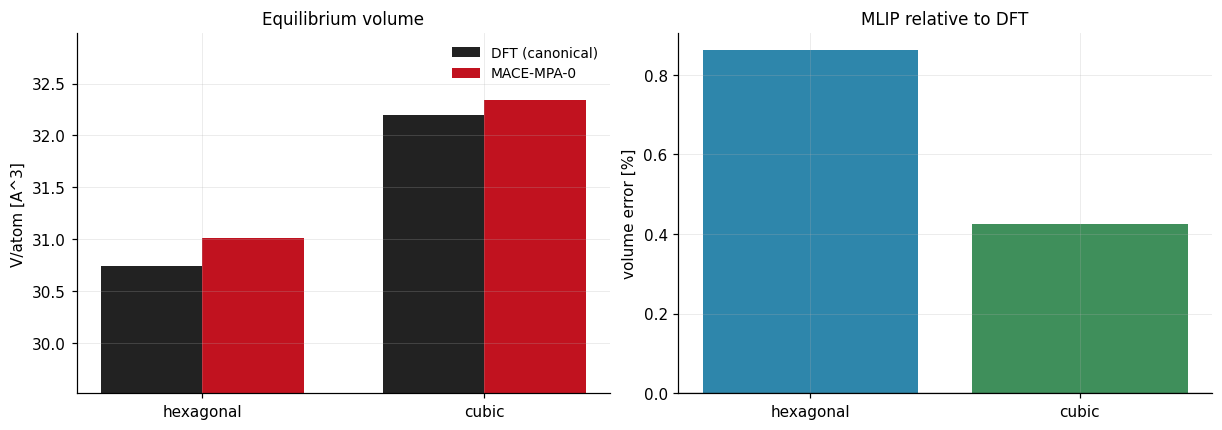

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
labels, mlip_v, dft_v = [], [], []
for row in rows:
    labels.append(row["相"].split(" ")[0])
    mlip_v.append(row["MLIP V/atom (A^3)"])
    dft_v.append(row["DFT V/atom (A^3)"])
x = np.arange(len(labels))
axes[0].bar(x - 0.18, dft_v, width=0.36, color="#222222", label="DFT (canonical)")
axes[0].bar(x + 0.18, mlip_v, width=0.36, color="#c1121f", label="MACE-MPA-0")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("V/atom [A^3]"); axes[0].set_title("Equilibrium volume")
axes[0].set_ylim(min(min(dft_v), min(mlip_v)) * 0.96, max(max(dft_v), max(mlip_v)) * 1.02)
axes[0].legend()

err = [100 * (m - d) / d for m, d in zip(mlip_v, dft_v)]
axes[1].bar(labels, err, color=["#2e86ab", "#3f8f5b"][: len(labels)])
axes[1].axhline(0, color="#222", lw=0.8)
axes[1].set_ylabel("volume error [%]"); axes[1].set_title("MLIP relative to DFT")
plt.show()

## 3. 相对能量与相序：四级阶梯

GST225 的相序是这个体系最基本的一道题：**相序错了，后面所有晶化/非晶化的结论都不可信**。

第一阶段只测了立方 vs 六角一个二元符号，但 `GST225_ref` 下其实有**四个**晶体参考、
DFT static 全部完成且协议相同，构成一条跨 54.7 meV/atom 的阶梯：

| 相 | 空间群 | DFT ΔE (meV/atom) |
|---|---|---|
| mp-1224375 | P-3m1 | 0（最低） |
| mp-3534 | P-3m1 | +15.13 |
| mp-1224407 | Cm | +37.81 |
| cubic（岩盐+空位，194 原子） | — | +54.65 |

两个 P-3m1 不是两个相，是三角相的**两种 Te–Ge–Te 堆垛序列**。它们之间那 15.13 meV/atom
是整条阶梯里分辨力最强的一格，也正是结晶路径研究需要的分辨率。

**为什么必须测全部六对而不是逐个对基准比**：`phase_ordering_metrics` 是拿每个相跟一个基准比；
当基准取 DFT 最低相时，「这个相高于基准」对所有相**按构造成立**——那个符号检验实际上只测了一对。
一个模型完全可以把最两端排对、把中间两级颠倒。`phase_ladder_metrics` 因此测全部
$\binom{4}{2}=6$ 对，并报 Kendall τ。

**一处必须一起引用的限定**：cubic 胞是 Ge₄₃Sb₄₃Te₁₀₈，**Te/Ge = 2.512 而非 2.500**
（精确 Ge₂Sb₂Te₅ 需要 107.5 个 Te）。模型与 DFT 看的是同一个胞，偏差是共模的、
逐级*误差*不受影响；但那 54.65 meV/atom 不能当作纯相变焓引用。

,metric,MLIP ΔE (meV/atom),DFT ΔE (meV/atom),误差 (meV/atom),相序是否复现,status
0,L2.phase_order.cubic_minus_hexagonal,44.95,54.65,-9.7,True,provisional


,phase,DFT ΔE,MLIP ΔE,误差
0,P-3m1 (mp-1224375),0.00,0.00,0.00
1,P-3m1 (mp-3534),15.13,13.09,-2.03
2,Cm (mp-1224407),37.81,42.54,4.73
3,cubic (rocksalt+vac),54.65,44.95,-9.70


inversions 0/6 pairs   Kendall tau +1.000   reference phase mp1224375


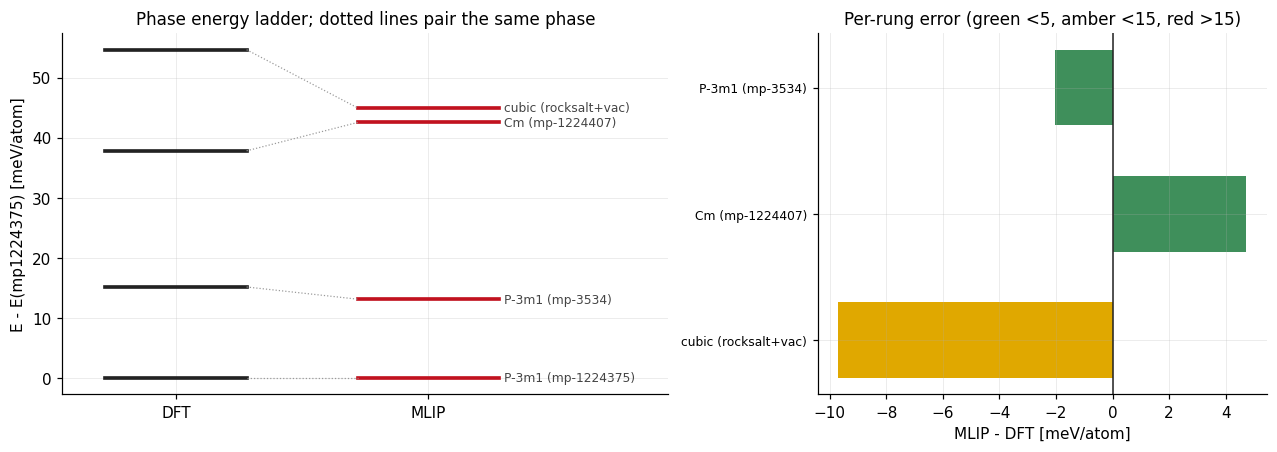

In [5]:
# --- the legacy binary, kept as the phase-1 continuity anchor --------------
order_rows = []
for k, r in by_id.items():
    if k.startswith("L2.phase_order"):
        e = r["extra"]
        order_rows.append({
            "metric": k, "MLIP ΔE (meV/atom)": r["value"],
            "DFT ΔE (meV/atom)": e.get("dft_meV_per_atom"),
            "误差 (meV/atom)": e.get("error_meV_per_atom"),
            "相序是否复现": e.get("ordering_reproduced"),
            "status": r["status"],
        })
display(pd.DataFrame(order_rows).round(2))

# --- the four-rung ladder --------------------------------------------------
inv = by_id.get("L2.phase_ladder.inversions")
if inv is None:
    print("no phase ladder in this result set: rerun run_l2.py")
else:
    dft_l = inv["extra"]["dft_ladder_meV_per_atom"]
    mlip_l = inv["extra"]["model_ladder_meV_per_atom"]
    base = inv["extra"]["reference_phase"]
    # plotted in DFT energy order, which is the order the model has to reproduce
    keys = sorted(dft_l, key=lambda k: dft_l[k])
    PHASE_LABEL = {"mp1224375": "P-3m1\n(mp-1224375)", "mp3534": "P-3m1\n(mp-3534)",
                   "mp1224407": "Cm\n(mp-1224407)", "cubic": "cubic\n(rocksalt+vac)"}

    display(pd.DataFrame([{
        "phase": PHASE_LABEL[k].replace("\n", " "),
        "DFT ΔE": dft_l[k], "MLIP ΔE": mlip_l[k], "误差": mlip_l[k] - dft_l[k],
    } for k in keys]).round(2))
    tau = by_id["L2.phase_ladder.kendall_tau"]["value"]
    print(f"inversions {int(inv['value'])}/{inv['extra']['n_pairs']} pairs   "
          f"Kendall tau {tau:+.3f}   reference phase {base}")
    if inv["extra"]["inverted_pairs"]:
        print("inverted:", inv["extra"]["inverted_pairs"])

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), width_ratios=[1.35, 1])

    # left: the ladder as levels, DFT against MLIP -- a rung plot, not bars,
    # because what matters is the vertical *order* and spacing, not the areas
    ax = axes[0]
    for x, (series, color) in enumerate([(dft_l, "#222222"), (mlip_l, "#c1121f")]):
        for k in keys:
            ax.plot([x - 0.28, x + 0.28], [series[k]] * 2, color=color, lw=2.4)
    # labelled once, on the DFT column: the dotted connectors below carry identity
    # across to the MLIP column, and two labels per rung is both redundant and the
    # only thing here that can collide (MACE puts Cm and cubic 2.4 meV/atom apart)
    for k in keys:
        ax.annotate(PHASE_LABEL[k].replace("\n", " "), (1.30, mlip_l[k]),
                    fontsize=8, va="center", ha="left", color="#444444")
    for k in keys:   # tie the two ladders together so a reordering is visible
        ax.plot([0.28, 0.72], [dft_l[k], mlip_l[k]], color="#999999", lw=0.8, ls=":")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["DFT", "MLIP"])
    ax.set_xlim(-0.45, 1.95)
    ax.set_ylabel(f"E - E({base}) [meV/atom]")
    ax.set_title("Phase energy ladder; dotted lines pair the same phase")

    # right: per-rung error
    ax = axes[1]
    rungs = [k for k in keys if k != base]
    err = [mlip_l[k] - dft_l[k] for k in rungs]
    ax.barh(np.arange(len(rungs)), err,
            color=["#c1121f" if abs(v) > 15 else "#e0a800" if abs(v) > 5 else "#3f8f5b"
                   for v in err], height=0.6)
    ax.axvline(0, color="#222222", lw=1.0)
    ax.set_yticks(np.arange(len(rungs)))
    ax.set_yticklabels([PHASE_LABEL[k].replace("\n", " ") for k in rungs], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("MLIP - DFT [meV/atom]")
    ax.set_title("Per-rung error (green <5, amber <15, red >15)")
    plt.show()

## 4. 固定体积 · 离子弛豫的 EOS

EOS 的构造必须与 phase-1 的 `H2_*` 任务一致：**各向同性缩放晶胞 → 固定体积 → 弛豫离子**。
拟合用三阶 Birch–Murnaghan，起点由抛物线拟合给出，避免非线性拟合发散。

$$E(V)=E_0+\frac{9V_0B_0}{16}\left[(\eta-1)^3B_0' + (\eta-1)^2(6-4\eta)\right],\quad \eta=(V_0/V)^{2/3}$$

In [6]:
def load_curve(name):
    path = paths.DATA / f"l2_eos_{name}.npz"
    if not path.exists():
        return None
    z = np.load(path, allow_pickle=False)
    return EOSCurve(label=str(z["label"]), volumes=z["volumes"], energies=z["energies"],
                    n_atoms=int(z["n_atoms"]), source=str(z["source"]))

curves = {name: load_curve(name) for name in ("hex_dft", "hex_mlip", "cubic_dft", "cubic_mlip")}
for name, c in curves.items():
    if c is None:
        print(f"{name:12s} 尚未生成")
    else:
        print(f"{name:12s} {len(c.volumes)} 点, {c.n_atoms} 原子 | {c.source[:90]}")

hex_dft      7 点, 9 原子 | phase-1 DFT tasks: H2_hex_v092, H2_hex_v095, H2_hex_v098, H2_hex_v100, H2_hex_v102, H2_hex
hex_mlip     7 点, 9 原子 | MACE-MPA-0 (medium) fixed-volume ionic-relaxed scan
cubic_dft    7 点, 194 原子 | phase-1 DFT tasks: H2_cub01_v092, H2_cub01_v095, H2_cub01_v098, H2_cub01_v100, H2_cub01_v1
cubic_mlip   7 点, 194 原子 | MACE-MPA-0 (medium) fixed-volume ionic-relaxed scan


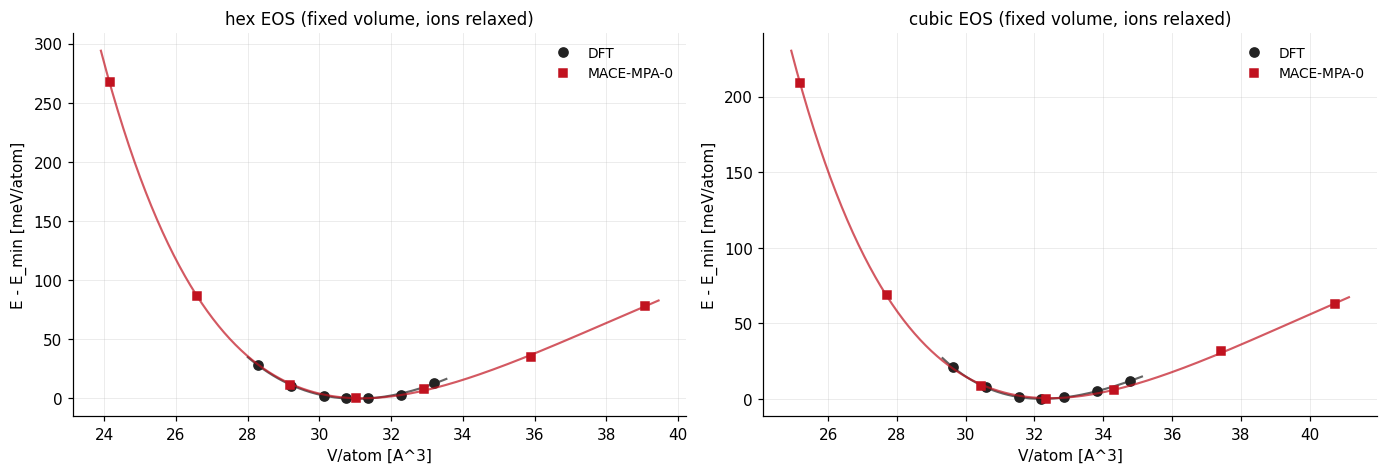

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

for ax, phase in zip(axes, ("hex", "cubic")):
    dft, mlip = curves.get(f"{phase}_dft"), curves.get(f"{phase}_mlip")
    plotted = False
    for curve, style in ((dft, dict(color="#222222", marker="o", ls="none", ms=6, label="DFT")),
                         (mlip, dict(color="#c1121f", marker="s", ls="none", ms=5, label="MACE-MPA-0"))):
        if curve is None or len(curve.volumes) < 4:
            continue
        v, e = curve.volume_per_atom, curve.energy_per_atom
        e = e - e.min()
        ax.plot(v, e * 1000, **style)
        fit = fit_eos(curve)
        if np.isfinite(fit.v0_per_atom):
            grid = np.linspace(v.min() * 0.99, v.max() * 1.01, 200)
            model = birch_murnaghan(grid, fit.e0_per_atom, fit.v0_per_atom,
                                    fit.b0_gpa * 0.006241509074, fit.bp)
            ax.plot(grid, (model - curve.energy_per_atom.min()) * 1000,
                    color=style["color"], lw=1.4, alpha=0.7)
        plotted = True
    ax.set_xlabel("V/atom [A^3]"); ax.set_ylabel("E - E_min [meV/atom]")
    ax.set_title(f"{phase} EOS (fixed volume, ions relaxed)")
    if plotted:
        ax.legend()
    else:
        ax.text(0.5, 0.5, "DFT EOS not yet available", transform=ax.transAxes, ha="center")
plt.show()

In [8]:
fit_rows = []
for name, curve in curves.items():
    if curve is None or len(curve.volumes) < 4:
        continue
    fit = fit_eos(curve)
    fit_rows.append({"曲线": name, **fit.to_dict()})
display(pd.DataFrame(fit_rows).round(4))

eos_metrics = pd.DataFrame([{
    "metric_id": k, "value": r["value"], "unit": r["unit"], "status": r["status"], "tier": r["evidence_tier"],
} for k, r in by_id.items() if k.startswith("L2.eos")])
display(eos_metrics.round(4))

,曲线,V0_A3_per_atom,E0_eV_per_atom,B0_GPa,Bp,fit_rmse_meV_per_atom,n_points,model
0,hex_dft,31.0275,-3.7777,31.0844,5.0889,0.6836,7,birch-murnaghan
1,hex_mlip,31.1753,-3.7938,25.6190,8.1337,0.8275,7,birch-murnaghan
2,cubic_dft,32.2258,-3.7226,24.3016,9.0738,0.0437,7,birch-murnaghan
3,cubic_mlip,32.4440,-3.7480,19.5993,8.1278,0.8510,7,birch-murnaghan


,metric_id,value,unit,status,tier
0,L2.eos.hex.V0,31.1753,A^3/atom,provisional,B
1,L2.eos.hex.B0,25.6190,GPa,provisional,B
2,L2.eos.hex.V0_error,0.4764,%,provisional,B
3,L2.eos.hex.B0_error,-17.5823,%,provisional,B
4,L2.eos.cubic.V0,32.4365,A^3/atom,provisional,B
5,L2.eos.cubic.B0,19.8618,GPa,provisional,B
6,L2.eos.cubic.V0_error,0.4865,%,provisional,B
7,L2.eos.cubic.B0_error,-15.4300,%,provisional,B
8,L2.eos.cubic.seed_ensemble.dft_V0_spread,0.0603,A^3/atom,provisional,B
9,L2.eos.cubic.seed_ensemble.dft_B0_spread,1.2477,GPa,provisional,B


## 5. 立方相 EOS：五种空位排布，逐 seed 配对

五条 `H2_cub0*` 曲线来自同一个 194 原子 rocksalt 胞的**五种空位排布**。
把它们当成"同一个量的五次测量"是错的——它们的散布衡量的是**立方相的 EOS 有多依赖空位怎么排**，
是相本身的性质，不是参考值的噪声，因此**不能进 `sigma_eff = max(sigma_ref, d_protocol/2)`**。

正确的用法是**逐 seed 配对**：MLIP 在同样五种排布上各弛豫、各扫 EOS，与对应的 DFT 曲线配对，
得到 5 个成对误差。这样"模型的系统偏差"（误差均值）和"偏差里随构型变的那部分"（误差散布）
才是分开的——单个 seed 无论如何分不开这两者。

最后一列 `|误差|/DFT散布` 是判据：**比值 < 1 表示模型的平均误差还没大过参考自己的构型抖动**，
那它就不构成对模型的判断。

In [9]:
per_seed_curves = {}
for s in range(1, 6):
    d, m = load_curve(f"cubic_s{s:02d}_dft"), load_curve(f"cubic_s{s:02d}_mlip")
    if d is not None and m is not None:
        per_seed_curves[f"s{s:02d}"] = (fit_eos(m), fit_eos(d))

if not per_seed_curves:
    print("尚无逐 seed 的立方相 EOS：请先跑 run_l2.py（--cubic-eos-seeds all）")
else:
    rows = []
    for key, (mf, df) in sorted(per_seed_curves.items()):
        rows.append({
            "seed": key,
            "DFT V0": df.v0_per_atom, "MLIP V0": mf.v0_per_atom,
            "V0 误差 (%)": 100 * (mf.v0_per_atom - df.v0_per_atom) / df.v0_per_atom,
            "DFT B0": df.b0_gpa, "MLIP B0": mf.b0_gpa,
            "B0 误差 (%)": 100 * (mf.b0_gpa - df.b0_gpa) / df.b0_gpa,
        })
    tbl = pd.DataFrame(rows)
    display(tbl.round(4))

    dft_v0_sd = tbl["DFT V0"].std(ddof=1) / tbl["DFT V0"].mean() * 100
    dft_b0_sd = tbl["DFT B0"].std(ddof=1) / tbl["DFT B0"].mean() * 100
    print(f"DFT 跨排布散布 : V0 {dft_v0_sd:.2f}% | B0 {dft_b0_sd:.2f}%   <- 参考自己的构型抖动")
    print(f"MLIP 平均误差  : V0 {tbl['V0 误差 (%)'].mean():+.2f}% "
          f"(sd {tbl['V0 误差 (%)'].std(ddof=1):.2f}) | "
          f"B0 {tbl['B0 误差 (%)'].mean():+.2f}% (sd {tbl['B0 误差 (%)'].std(ddof=1):.2f})")
    for nm, sd in (("V0", dft_v0_sd), ("B0", dft_b0_sd)):
        ratio = abs(tbl[f"{nm} 误差 (%)"].mean()) / sd
        verdict = "可分辨" if ratio > 1 else "埋在构型抖动里"
        print(f"  |{nm} 误差|/DFT散布 = {ratio:.2f}  -> {verdict}")


,seed,DFT V0,MLIP V0,V0 误差 (%),DFT B0,MLIP B0,B0 误差 (%)
0,s01,32.2258,32.4440,0.6770,24.3016,19.5993,-19.3499
1,s02,32.2055,32.3123,0.3316,23.6961,20.2942,-14.3566
2,s03,32.3362,32.5926,0.7926,24.2607,19.2220,-20.7688
3,s04,32.2993,32.3977,0.3045,24.0483,20.8976,-13.1014
4,s05,32.3304,32.4360,0.3266,21.3388,19.2960,-9.5733


DFT 跨排布散布 : V0 0.19% | B0 5.30%   <- 参考自己的构型抖动
MLIP 平均误差  : V0 +0.49% (sd 0.23) | B0 -15.43% (sd 4.60)
  |V0 误差|/DFT散布 = 2.60  -> 可分辨
  |B0 误差|/DFT散布 = 2.91  -> 可分辨


/var/folders/ly/np3n926x7t1fsg2y0fg7jqnh0000gn/T/ipykernel_29429/2826133489.py:41: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


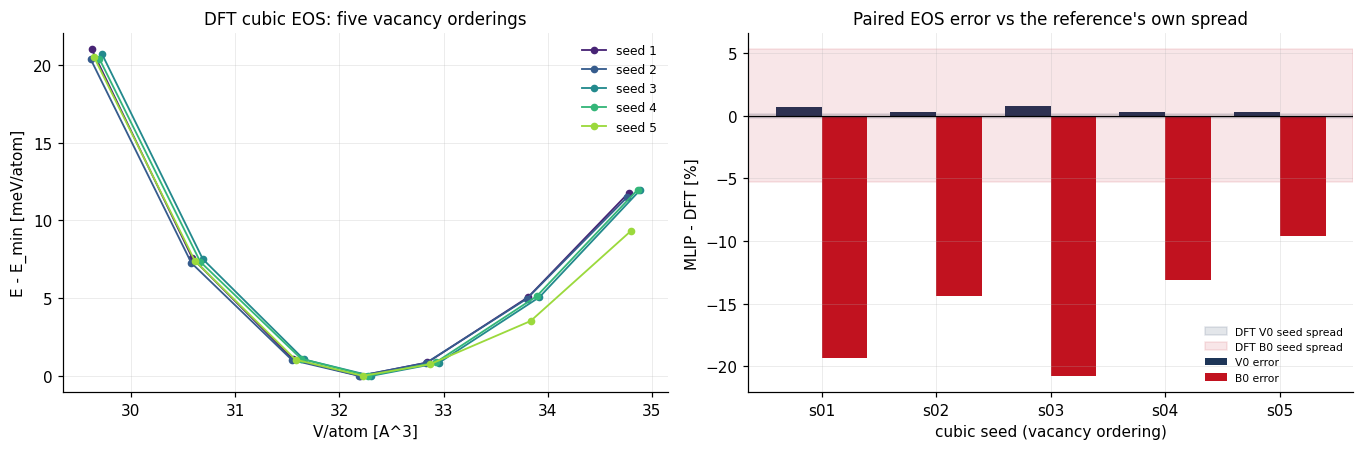

In [10]:
if per_seed_curves:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    colors = plt.cm.viridis(np.linspace(0.1, 0.85, 5))

    # left: the five DFT ladders, showing how much the reference itself moves
    ax = axes[0]
    for c, s in zip(colors, range(1, 6)):
        curve = load_curve(f"cubic_s{s:02d}_dft")
        if curve is None:
            continue
        v, e = curve.volume_per_atom, curve.energy_per_atom
        ax.plot(v, (e - e.min()) * 1000, "o-", color=c, ms=4, lw=1.2,
                label=f"seed {s}")
    ax.set_xlabel("V/atom [A^3]"); ax.set_ylabel("E - E_min [meV/atom]")
    ax.set_title("DFT cubic EOS: five vacancy orderings")
    ax.legend(fontsize=8)

    # right: the paired errors, against the reference's own spread
    ax = axes[1]
    keys = sorted(per_seed_curves)
    x = np.arange(len(keys))
    v0e = [100 * (per_seed_curves[k][0].v0_per_atom - per_seed_curves[k][1].v0_per_atom)
           / per_seed_curves[k][1].v0_per_atom for k in keys]
    b0e = [100 * (per_seed_curves[k][0].b0_gpa - per_seed_curves[k][1].b0_gpa)
           / per_seed_curves[k][1].b0_gpa for k in keys]
    ax.bar(x - 0.2, v0e, 0.4, color="#1d3557", label="V0 error")
    ax.bar(x + 0.2, b0e, 0.4, color="#c1121f", label="B0 error")
    dft_v0 = np.array([per_seed_curves[k][1].v0_per_atom for k in keys])
    dft_b0 = np.array([per_seed_curves[k][1].b0_gpa for k in keys])
    ax.axhspan(-100 * dft_v0.std(ddof=1) / dft_v0.mean(),
               100 * dft_v0.std(ddof=1) / dft_v0.mean(),
               color="#1d3557", alpha=0.12, label="DFT V0 seed spread")
    ax.axhspan(-100 * dft_b0.std(ddof=1) / dft_b0.mean(),
               100 * dft_b0.std(ddof=1) / dft_b0.mean(),
               color="#c1121f", alpha=0.10, label="DFT B0 seed spread")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(keys)
    ax.set_xlabel("cubic seed (vacancy ordering)"); ax.set_ylabel("MLIP - DFT [%]")
    ax.set_title("Paired EOS error vs the reference's own spread")
    ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


## 5. 为什么必须坚持"固定体积 + 离子弛豫"

`load_dft_eos` 对 `NSW <= 0` 的任务直接拒绝并记录理由。下面把这个拒绝行为显式跑一遍，
说明它不是可选的礼貌提示，而是一道硬门。

In [11]:
from mlipeval.io_vasp import read_incar, task_output_dir

hex_tasks = datasets.dft_eos_tasks("hex")
tag_rows = []
for d in hex_tasks:
    tags = read_incar(task_output_dir(d) / "INCAR")
    tag_rows.append({"task": d.name, "NSW": tags.get("NSW"), "IBRION": tags.get("IBRION"),
                     "ISIF": tags.get("ISIF"), "ENCUT": tags.get("ENCUT"), "KSPACING": tags.get("KSPACING")})
display(pd.DataFrame(tag_rows))

strict = load_dft_eos(hex_tasks, label="hex", require_ionic_relaxation=True)
print(f"\n严格模式收下 {len(strict.volumes)} 个点，拒绝 {len(getattr(strict, 'skipped', []))} 个")
for note in getattr(strict, "skipped", []):
    print("  拒绝:", note)

,task,NSW,IBRION,ISIF,ENCUT,KSPACING
0,H2_hex_v092,160,2,2,500,0.20
1,H2_hex_v095,160,2,2,500,0.20
2,H2_hex_v098,160,2,2,500,0.20
3,H2_hex_v100,160,2,2,500,0.20
4,H2_hex_v102,160,2,2,500,0.20
5,H2_hex_v105,160,2,2,500,0.20
6,H2_hex_v108,160,2,2,500,0.20



严格模式收下 7 个点，拒绝 0 个


## 6. 全部 L2 结果

In [12]:
frame = pd.DataFrame([{
    "metric_id": r["metric_id"], "value": r["value"], "unit": r["unit"],
    "status": r["status"], "tier": r["evidence_tier"], "failure_reason": r.get("failure_reason"),
} for r in results["results"]])
display(frame)
print("状态分布:", frame.status.value_counts().to_dict())
print("\n为什么是 provisional：", results["context"]["note"])

,metric_id,value,unit,status,tier,failure_reason
0,L2.relax.hex_mp1224375.energy_per_atom,-3.793350,eV/atom,ok,S,None
1,L2.relax.hex_mp1224375.volume_error,0.860842,%,provisional,B,None
2,L2.relax.hex_mp1224375.cell_length_error,1.170529,%,provisional,B,None
3,L2.relax.cubic_s01.energy_per_atom,-3.748400,eV/atom,ok,S,None
4,L2.relax.cubic_s01.volume_error,0.425624,%,provisional,B,None
5,L2.relax.cubic_s01.cell_length_error,0.188979,%,provisional,B,None
6,L2.phase_order.cubic_minus_hexagonal,44.949649,meV/atom,provisional,B,None
7,L2.relax.phase_mp3534.energy_per_atom,-3.780256,eV/atom,ok,S,None
8,L2.relax.phase_mp3534.volume_error,0.689251,%,provisional,B,None
9,L2.relax.phase_mp3534.cell_length_error,0.789016,%,provisional,B,None


状态分布: {'provisional': 36, 'ok': 9}

为什么是 provisional： every comparison is provisional (validation_methods_L0-L5.md section 4). The cubic EOS now has five DFT references, but they are five vacancy orderings rather than five repeats, so their spread is configurational and is not usable as sigma_ref; the hexagonal side still has a single reference.


## 7. 组成修正的形成能

相序阶梯只比较同组成（GST225）的相对能量。**形成能**还要求模型把三种单质也放对：

$$\Delta H_f = E/N - \sum_X x_X\,\mu_X$$

两侧各用自己的单质参考——DFT 用 `L2_{ge,sb,te}_static`，模型用自己弛豫过的单质胞（与 DFT 弛豫同一起点）。
这样协议之间的逐元素常数偏移相互抵消，剩下的是模型对"化合 vs 单质"能量差的误差。
cubic 胞是 Ge₄₃Sb₄₃Te₁₀₈，与六方相组成不同，所以**组成修正后的** cubic−hex 差比第 3 节的
直接能量差更干净：两相都参照单质基态，Te/Ge = 2.512 的组成偏离也被吸收掉。

,MLIP 弛豫 E (eV/atom),体积误差 (%),胞长误差 (%)
element,,,
Ge,-4.610,-2.917,0.982
Sb,-4.117,1.058,2.371
Te,-3.098,-6.810,7.055


,mu DFT (eV/atom),mu MLIP (eV/atom)
Ge,-4.49374,-4.61027
Sb,-4.14363,-4.11690
Te,-3.14587,-3.09788


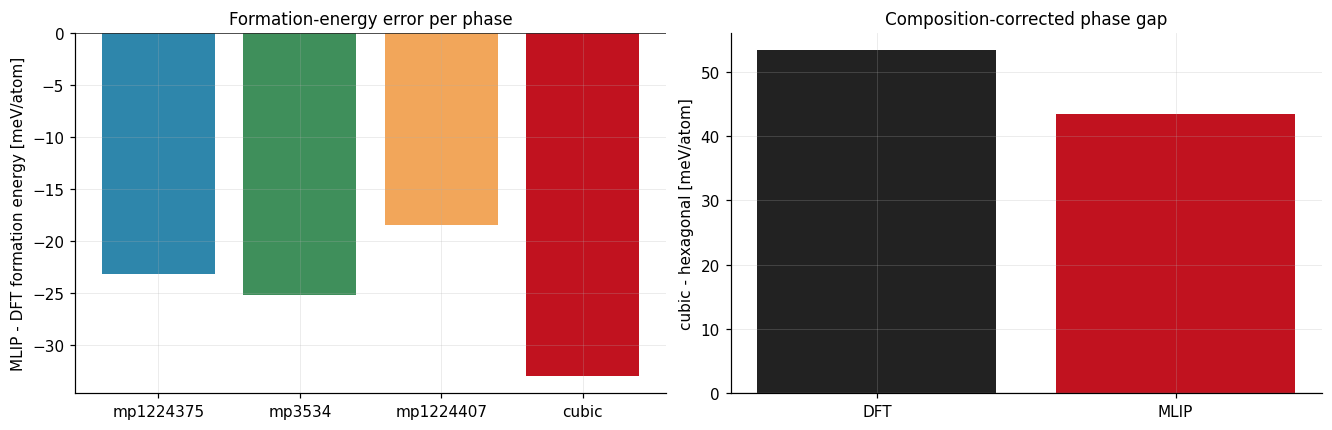

,metric_id,value,unit,status,tier
0,L2.formation_energy.dE_error.mp1224375,-23.164,meV/atom,provisional,B
1,L2.formation_energy.dE_error.mp3534,-25.198,meV/atom,provisional,B
2,L2.formation_energy.dE_error.mp1224407,-18.434,meV/atom,provisional,B
3,L2.formation_energy.dE_error.cubic,-32.968,meV/atom,provisional,B
4,L2.formation_energy.cubic_minus_hexagonal,43.500,meV/atom,provisional,B


ordering reproduced: True | both phases referenced to the element ground states (composition-corrected)


In [13]:
elements = pd.DataFrame([{
    "element": el,
    "MLIP 弛豫 E (eV/atom)": by_id[f"L2.relax.element_{el}.energy_per_atom"]["value"],
    "体积误差 (%)": by_id[f"L2.relax.element_{el}.volume_error"]["value"],
    "胞长误差 (%)": by_id[f"L2.relax.element_{el}.cell_length_error"]["value"],
} for el in ("Ge", "Sb", "Te")]).set_index("element")
display(elements.round(3))

gap = by_id["L2.formation_energy.cubic_minus_hexagonal"]
mu = pd.DataFrame({"mu DFT (eV/atom)": gap["extra"]["mu_dft_eV_per_atom"],
                   "mu MLIP (eV/atom)": gap["extra"]["mu_model_eV_per_atom"]})
display(mu.round(5))

phases = ["mp1224375", "mp3534", "mp1224407", "cubic"]
err = [by_id[f"L2.formation_energy.dE_error.{p}"]["value"] for p in phases]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(phases, err, color=["#2e86ab", "#3f8f5b", "#f2a65a", "#c1121f"])
axes[0].axhline(0, color="#222", lw=1.0)
axes[0].set_ylabel("MLIP - DFT formation energy [meV/atom]")
axes[0].set_title("Formation-energy error per phase")

axes[1].bar(["DFT", "MLIP"], [gap["extra"]["dft_meV_per_atom"], gap["value"]], color=["#222222", "#c1121f"])
axes[1].axhline(0, color="#999", lw=0.8)
axes[1].set_ylabel("cubic - hexagonal [meV/atom]")
axes[1].set_title("Composition-corrected phase gap")
plt.show()

display(pd.DataFrame([{"metric_id": k, "value": r["value"], "unit": r["unit"], "status": r["status"],
                       "tier": r["evidence_tier"]}
                      for k, r in by_id.items() if k.startswith("L2.formation_energy")]).round(3))
print("ordering reproduced:", gap["extra"]["ordering_reproduced"], "|", gap["extra"]["note"])

（读法在执行后填写。）

## 小结

**已完成**

- 六角相与立方相的 MLIP 变胞弛豫，与同协议 DFT 弛豫逐项对照（体积、胞长、能量）；
- **四级相序阶梯**：两个 P-3m1 堆垛、单斜 Cm、立方岩盐+空位，全部六对顺序检验 + Kendall τ
  + 逐级 ΔE 误差。第一阶段的立方 vs 六角二元判定保留为连续性锚点；
- 六角相 EOS：DFT 侧 7 个已完成的固定体积离子弛豫点 vs MLIP 同构造扫描，
  两侧都做三阶 Birch–Murnaghan 拟合，报告 $V_0$ 与 $B_0$；
- **立方相 EOS：DFT 侧五个空位排布全部完成（5 × 7 = 35 点）**，MLIP 在同样五种排布上
  各扫一遍，逐 seed 配对。报告的 `L2.eos.cubic.V0_error` 是 5 个成对误差的均值，
  `uncertainty` 是跨排布标准差——模型的系统偏差与其构型依赖被分开。

**为什么从二元换成阶梯**

原来的符号检验难度接近抛硬币——它拿每个相跟基准比，而基准取 DFT 最低相时
「高于基准」按构造成立，实际只测了一对。四级阶梯里中间两级才是难的：
两个 P-3m1 只差 15.13 meV/atom。这两个结构（`mp-3534`、`mp-1224407`）的 DFT static
第一阶段就已算完，只是没有任何 driver 引用——**是覆盖缺口，不是数据缺口**。

**限制**

- 六角相只有一条 DFT 参考，`sigma_ref` 未知，标 `provisional`；
- 立方相虽有五条参考，但那是**五种空位排布而非五次重复**，散布是构型性的，
  **不能当 `sigma_ref`**，因此同样标 `provisional`。它能支撑的结论只有一个：
  模型的平均误差是否大过参考自己的构型抖动（见第 5 节的比值判据）；
- 逐 seed 的误差**只发一条聚合 metric**。ranking 的 EOS 指标用 `_mean_abs` 聚合
  `^L2\.eos\..*\.V0_error$`，发 5 条会让立方相在跨模型总分里拿到六倍于六方相的权重；
- cubic 胞 Te/Ge = 2.512 而非 2.500；共模、不影响误差，但绝对值不是相变焓。

**待补**（框架 6 节的补数据建议里，L2 类失败对应的条目）

- 若 EOS 或相序出现偏差，优先补 cubic/hexagonal 的应变结构与固定体积弛豫结构；
- 声子、弹性常数、缺陷与表面/界面性质按框架安排留到第一阶段跑通之后。